# №9 зертханалық жұмыс
## Ансамбльдік модельдер мен градиенттік бустинг әдістерін құру және салыстыру: Gradient Boosting, XGBoost, LightGBM және CatBoost.

Алдымен синтетикалық регрессияда бустинг кезеңдерінің санын таңдаймыз. Кейін WDBC жиынында алдын ала берілген төрт жіктеуіш пен ортақ DummyPrior моделін салыстырамыз. Индекстер, бағалар, CSV және екі сурет `lab09_artifacts` каталогына сақталады. WDBC оқу талдауы бір кестелік жиынға және оның бекітілген бөлінуіне қатысты.

### 1-қадам. Орта және бағалау жоспарлары

Кітапхана нұсқаларын жазыңыз. Регрессия үшін таңдаудың негізгі критерийі — validation RMSE. Жіктеу үшін ықтималдықтар бойынша ROC-AUC және 0,5 шегіндегі белгілер бойынша macro-F1 хабарланады.

In [1]:
from pathlib import Path
from importlib.metadata import version
import json
import os
import platform

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer, make_friedman1
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.metrics import f1_score, mean_absolute_error, roc_auc_score, roc_curve
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

ROOT = Path.cwd() / "lab09_artifacts"
FIGURES = ROOT / "figures"
DATASETS = ROOT / "datasets"
FIGURES.mkdir(parents=True, exist_ok=True)
DATASETS.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"
ATTRIBUTION = """Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993).
Breast Cancer Wisconsin (Diagnostic). UCI Machine Learning Repository.
DOI: https://doi.org/10.24432/C5DW2B
Дереккөз: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
Лицензия: CC BY 4.0 https://creativecommons.org/licenses/by/4.0/
scikit-learn load_breast_cancer кірістірілген көшірмесінен экспорт.
Белгі атауларындағы бос орындар астын сызу таңбаларына ауыстырылған. Мақсатты айнымалы sklearn target 0 үшін malignant=1
және sklearn target 1 үшін malignant=0 ретінде қайта кодталған. row_id және split —
осы сабаққа қосылған қызметтік өрістер. Метадеректер 2026-11-05 күні тексерілген.
"""
PACKAGES = ("numpy", "pandas", "scikit-learn", "matplotlib", "threadpoolctl",
            "xgboost", "lightgbm", "catboost", "IPython")
THREAD_ENVIRONMENT = ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                      "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS")



from IPython.display import display, Image
for package in PACKAGES:
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scikit-learn 1.9.1
matplotlib 3.11.2
threadpoolctl 3.7.0
xgboost 3.4.1
lightgbm 4.7.0
catboost 1.2.10
IPython 9.18.1


### 2-қадам. Friedman1 жасау және бөлу

600 жол мен сегіз кіріс, шу 1,5, генерация тұқымы 2026. Алдымен seed 2026 арқылы 120 test жолын бөлеміз. Қалған 480 жолдан seed 2027 арқылы 120 validation жолын бөлеміз. Бірінші оқыту 360 train жолын пайдаланады.

In [2]:
def make_regression_data():
    X, y = make_friedman1(n_samples=600, n_features=8, noise=1.5, random_state=2026)
    development, test = train_test_split(np.arange(len(y)), test_size=.2, random_state=2026)
    train, validation = train_test_split(development, test_size=.25, random_state=2027)
    return {"X": X, "y": y, "train": train, "validation": validation,
            "test": test, "development": development}



regression_data = make_regression_data()
print("train, validation, test өлшемдері", [len(regression_data[name])
      for name in ("train", "validation", "test")])


train, validation, test өлшемдері [360, 120, 120]


### 3–4-қадамдар. validation бойынша кезең таңдау

150 кезең, 2 тереңдігі және 0,05 жылдамдығын береміз. Бір тізбек train жиынында оқытылады, ал staged_predict оның префикстерінің болжамдарын береді. validation RMSE ең аз болатын алғашқы кезең таңдалады.

In [3]:
def select_regression_stage(data):
    X, y = data["X"], data["y"]
    train, validation = data["train"], data["validation"]
    model = GradientBoostingRegressor(n_estimators=150, max_depth=2,
                                      learning_rate=.05, random_state=2026)
    with threadpool_limits(limits=1):
        model.fit(X[train], y[train])
        curve = [root_mean_squared_error(y[validation], prediction)
                 for prediction in model.staged_predict(X[validation])]
    best_n = int(np.argmin(curve)) + 1
    print("1, таңдалған және 150 кезеңдегі валидациялық RMSE:", curve[0], curve[best_n - 1], curve[-1])
    print("Таңдалған кезеңдер:", best_n)
    return {"best_n": best_n, "validation_curve": curve, "fit_rows": len(train),
            "estimator_parameters": model.get_params()}



selection = select_regression_stage(regression_data)


1, таңдалған және 150 кезеңдегі валидациялық RMSE: 5.086816089232065 2.234927740751218 2.236670910603297
Таңдалған кезеңдер: 149


### 5–6-қадамдар. Қайта оқыту (refit) және қорытынды қателер

Таңдалған кезеңдер саны жаңа ансамбльге көшіріледі. Қайта оқыту мен базалық орташа мән бірдей 480 жолды пайдаланады. Қорытынды ансамбль 120 test жолында бағаланады. Суреттің сол панелі таңдауға қатысты, оң панелі әр объектідегі бір қорытынды болжамды көрсетеді.

                       model  stages     RMSE      MAE
Train+validation орташа мәні       0 5.351507 4.142774
           Gradient Boosting     149 2.457460 1.935905


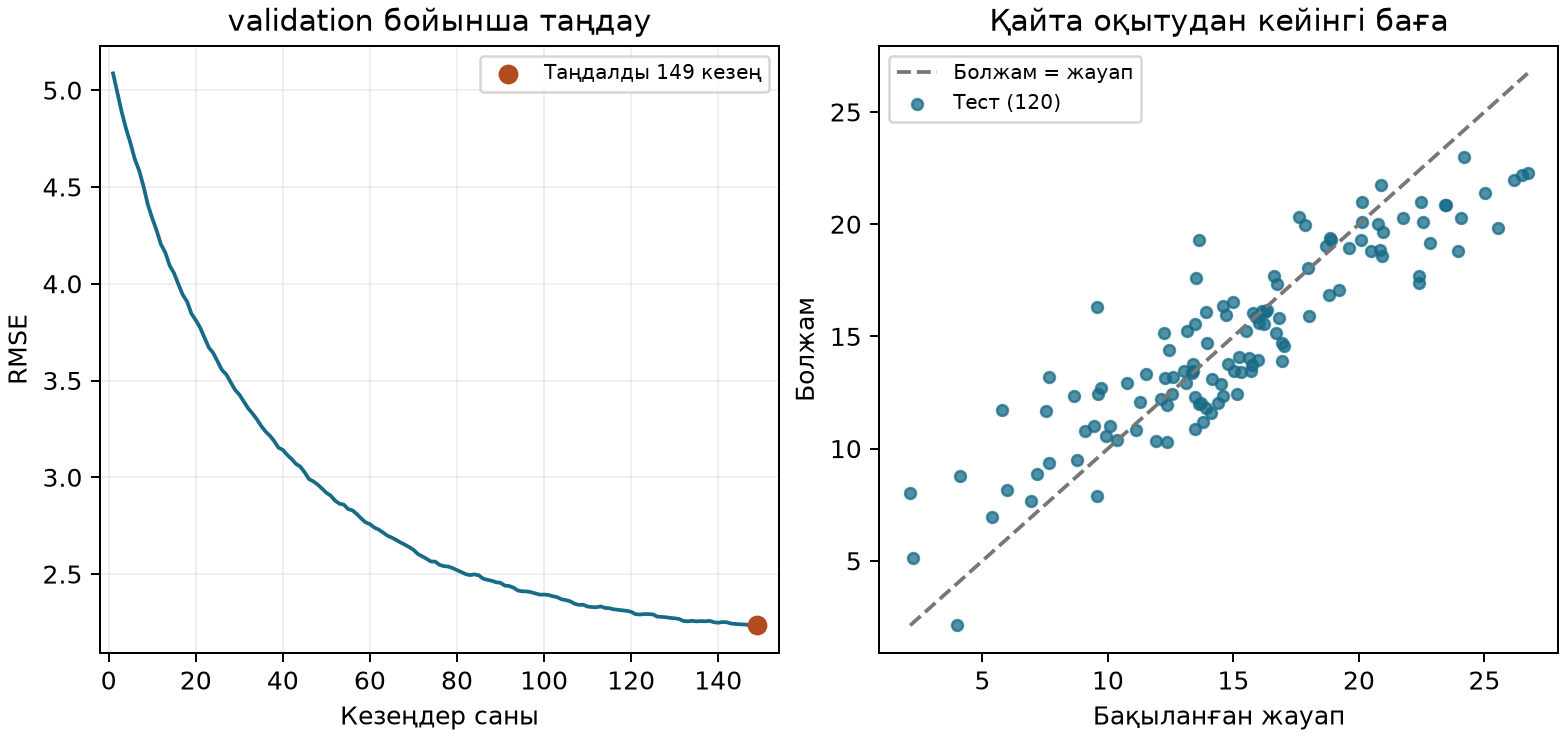

In [4]:
def evaluate_regression(data, selection):
    X, y = data["X"], data["y"]
    development, test = data["development"], data["test"]
    best_n = selection["best_n"]
    final = GradientBoostingRegressor(n_estimators=best_n, max_depth=2,
                                      learning_rate=.05, random_state=2026)
    with threadpool_limits(limits=1):
        final.fit(X[development], y[development])
        prediction = final.predict(X[test])
    baseline_mean = float(y[development].mean())
    baseline = np.full(len(test), baseline_mean)
    rows = [{"model": name, "stages": stages,
             "RMSE": float(root_mean_squared_error(y[test], predicted)),
             "MAE": float(mean_absolute_error(y[test], predicted))}
            for name, stages, predicted in [("Train+validation орташа мәні", 0, baseline),
                                             ("Gradient Boosting", best_n, prediction)]]
    print(pd.DataFrame(rows).to_string(index=False))
    fig, axes = plt.subplots(1, 2, figsize=(8.7, 4.1), layout="constrained")
    curve = selection["validation_curve"]
    axes[0].plot(range(1, len(curve) + 1), curve, color="#176B87")
    axes[0].scatter([best_n], [curve[best_n - 1]], s=48, color="#B34B20",
                    label=f"Таңдалды {best_n} кезең", zorder=3)
    axes[0].set(xlabel="Кезеңдер саны", ylabel="RMSE", title="validation бойынша таңдау",
                xlim=(-2, len(curve) + 4))
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=.2)
    low = min(y[test].min(), prediction.min())
    high = max(y[test].max(), prediction.max())
    axes[1].plot([low, high], [low, high], color="#777777", linestyle="--", label="Болжам = жауап")
    axes[1].scatter(y[test], prediction, s=19, alpha=.75, color="#176B87", label="Тест (120)")
    axes[1].set(xlabel="Бақыланған жауап", ylabel="Болжам", title="Қайта оқытудан кейінгі баға")
    axes[1].legend(fontsize=8, loc="upper left")
    fig.savefig(FIGURES / "ch09_05_regression.png", dpi=180)
    plt.close(fig)
    return {"shape": [600, 8], "synthetic": True, "noise": 1.5,
            "generator_seed": 2026, "test_split_seed": 2026, "validation_split_seed": 2027,
            "train_indices": data["train"].tolist(), "validation_indices": data["validation"].tolist(),
            "test_indices": test.tolist(), "selection_fit_rows": selection["fit_rows"],
            "refit_rows": len(development), "selected_n": best_n, "refit_n": int(final.n_estimators_),
            "selection_estimator_parameters": selection["estimator_parameters"],
            "refit_estimator_parameters": final.get_params(),
            "validation_RMSE": curve, "selected_validation_RMSE": curve[best_n - 1],
            "tie_rule": "алғашқы минимум, демек кезеңдердің ең аз саны",
            "test_used_for_selection": False, "test_model_prediction_calls": 1,
            "baseline_mean": baseline_mean, "test_rows": rows,
            "test_y": y[test].tolist(), "test_predictions": prediction.tolist()}



regression = evaluate_regression(regression_data, selection)
display(Image(filename=str(FIGURES / "ch09_05_regression.png")))


**Сіздің жауабыңыз.** validation жиынындағы 149- және 150-кезеңдер қателерінің жақындығын түсіндіріңіз. Кезеңдер санын сақтау refit кезінде ағаштардың өзгеруімен неліктен үйлеседі? Қорытынды кестенің екі жолын салыстырыңыз.

_Өз қорытындыңызды жазыңыз._

### 7-қадам. WDBC және бекітілген баптаулар

569 жол және 30 белгі. Оң класс malignant = (target == 0) ретінде алынады. Бөліну seed 2026 арқылы стратификацияланған. Баған атауларынан бос орындар алынып, train мен test жиындарында сақталады. 100 итерация, 3 тереңдігі және 0,05 жылдамдығы берілген. Қосымша шектеулер конструкторларда көрсетілген. [WDBC және CC BY 4.0 лицензиясы](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic).

In [5]:
def make_classification_data():
    data = load_breast_cancer()
    columns = [name.replace(" ", "_") for name in data.feature_names]
    X = pd.DataFrame(data.data, columns=columns)
    y = (data.target == 0).astype(int)
    train, test = train_test_split(np.arange(len(y)), test_size=.2, stratify=y, random_state=2026)
    return {"X": X, "y": y, "train": train, "test": test}


def fixed_classifiers():
    from catboost import CatBoostClassifier
    from lightgbm import LGBMClassifier
    from xgboost import XGBClassifier

    common = {"n_estimators": 100, "max_depth": 3, "learning_rate": .05, "random_state": 2026}
    return {
        "DummyPrior": DummyClassifier(strategy="prior"),
        "Gradient Boosting": GradientBoostingClassifier(**common),
        "XGBoost": XGBClassifier(**common, n_jobs=1, tree_method="hist",
                                  eval_metric="logloss", verbosity=0),
        "LightGBM": LGBMClassifier(**common, num_leaves=8, n_jobs=1,
                                    deterministic=True, force_col_wise=True, verbosity=-1),
        "CatBoost": CatBoostClassifier(iterations=100, depth=3, learning_rate=.05,
                                        random_seed=2026, thread_count=1, verbose=False,
                                        loss_function="Logloss", allow_writing_files=False),
    }



classification_data = make_classification_data()
models = fixed_classifiers()
print("WDBC бөліктерінің өлшемдері", len(classification_data["train"]), len(classification_data["test"]))
print("train кластары", np.bincount(classification_data["y"][classification_data["train"]]))


WDBC бөліктерінің өлшемдері 455 114
train кластары [285 170]


### 8–9-қадамдар. Оқыту және ортақ test бағалауы

Әр модель 455 жолда оқытылады. Оқытудан кейін 114 жол үшін 1 класының ықтималдықтарын сақтаймыз. ROC-AUC олардың ретін, macro-F1 0,5 шегіндегі белгілерді пайдаланады. Кесте нақты кезеңдер санын хабарлайды. Сурет сол бағаларды қолданады.

            model  stages  ROC_AUC  macro_F1
       DummyPrior       0 0.500000  0.387097
Gradient Boosting     100 0.996693  0.953106
          XGBoost     100 0.997024  0.962302
         LightGBM     100 0.995701  0.962302
         CatBoost     100 0.995370  0.962660


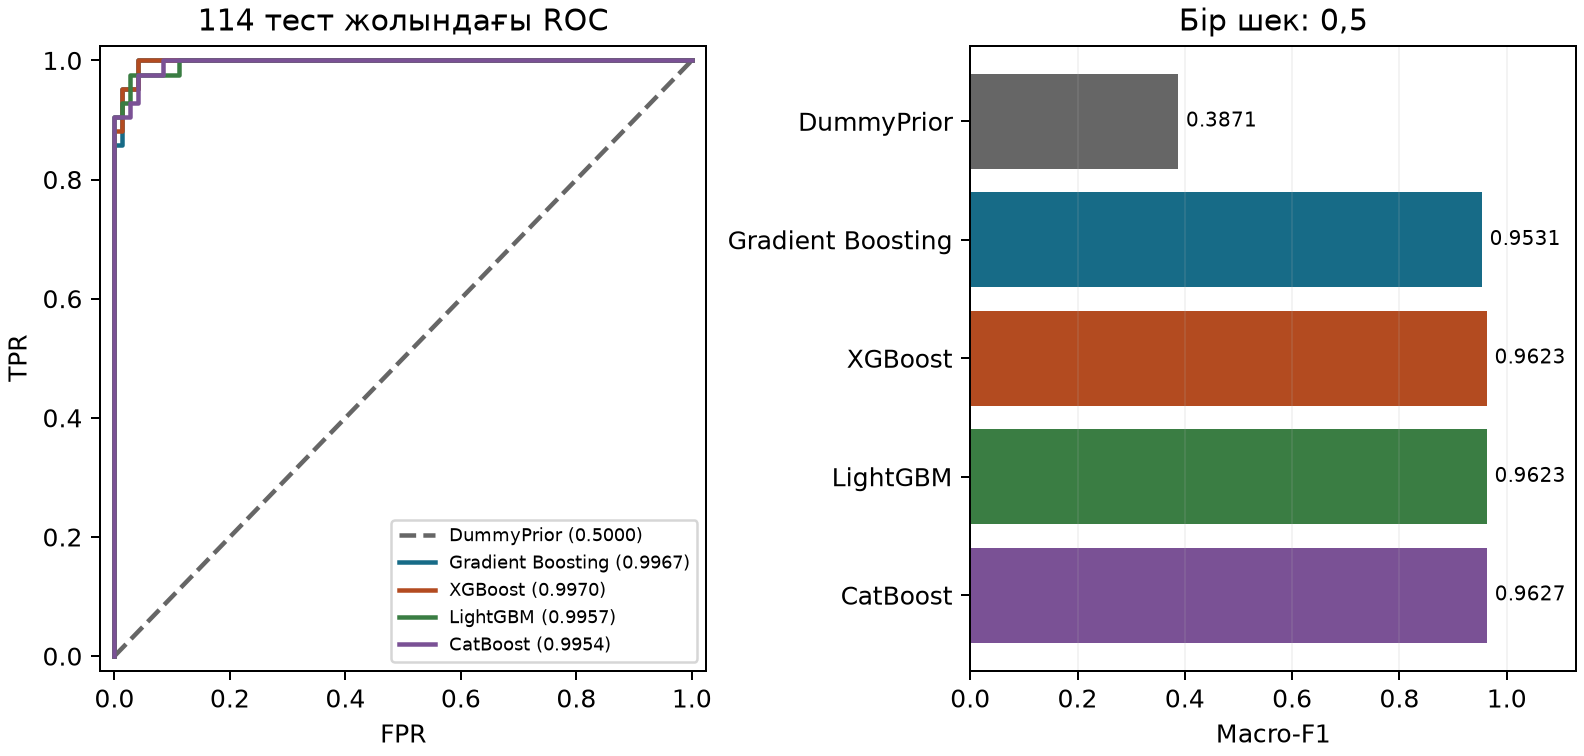

In [6]:
def evaluate_classification(data, models):
    X, y = data["X"], data["y"]
    train, test = data["train"], data["test"]
    rows, probabilities = [], {}
    with threadpool_limits(limits=1):
        for model in models.values():
            model.fit(X.iloc[train], y[train])
        for name, model in models.items():
            column = int(np.flatnonzero(model.classes_ == 1)[0])
            prediction_options = {"thread_count": 1} if name == "CatBoost" else {}
            score = model.predict_proba(X.iloc[test], **prediction_options)[:, column]
            predicted = (score >= .5).astype(int)
            probabilities[name] = score.tolist()
            if name == "DummyPrior":
                stages = 0
            elif name == "XGBoost":
                stages = model.get_booster().num_boosted_rounds()
            elif name == "CatBoost":
                stages = model.tree_count_
            else:
                stages = model.n_estimators_
            rows.append({"model": name, "stages": int(stages),
                         "ROC_AUC": float(roc_auc_score(y[test], score)),
                         "macro_F1": float(f1_score(y[test], predicted, average="macro", zero_division=0))})
    print(pd.DataFrame(rows).to_string(index=False))
    fig, axes = plt.subplots(1, 2, figsize=(8.8, 4.2), layout="constrained")
    colors = ["#666666", "#176B87", "#B34B20", "#3A7D43", "#7A5195"]
    for row, color in zip(rows, colors):
        name = row["model"]
        fpr, tpr, _ = roc_curve(y[test], probabilities[name], pos_label=1)
        axes[0].plot(fpr, tpr, color=color, linestyle="--" if name == "DummyPrior" else "-",
                     linewidth=1.8, label=f"{name} ({row['ROC_AUC']:.4f})")
    axes[0].set(xlabel="FPR", ylabel="TPR", title="114 тест жолындағы ROC",
                xlim=(-.025, 1.025), ylim=(-.025, 1.025))
    axes[0].legend(fontsize=7.2, loc="lower right")
    positions = np.arange(len(rows))
    scores = [row["macro_F1"] for row in rows]
    axes[1].barh(positions, scores, color=colors)
    for position, score in zip(positions, scores):
        axes[1].text(score + .015, position, f"{score:.4f}", va="center", fontsize=8)
    axes[1].set(yticks=positions, yticklabels=[row["model"] for row in rows],
                xlabel="Macro-F1", title="Бір шек: 0,5", xlim=(0, 1.13))
    axes[1].invert_yaxis()
    axes[1].grid(axis="x", alpha=.15)
    fig.savefig(FIGURES / "ch09_06_classification.png", dpi=180)
    plt.close(fig)
    parameters = {name: model.get_params() for name, model in models.items()}
    # XGBoost әдепкі жетіспейтін мән белгісі ретінде NaN қолданады. Оны қатаң JSON ішінде сақтаймыз.
    parameters["XGBoost"]["missing"] = "NaN"
    return {"shape": [569, 30], "synthetic": False, "DOI": "10.24432/C5DW2B",
            "license": "CC BY 4.0", "positive_class": "malignant=1", "split_seed": 2026,
            "train_indices": train.tolist(), "test_indices": test.tolist(),
            "train_counts_0_1": np.bincount(y[train], minlength=2).tolist(),
            "test_counts_0_1": np.bincount(y[test], minlength=2).tolist(),
            "threshold": .5, "test_used_for_selection": False,
            "estimator_classes": {name: type(model).__name__ for name, model in models.items()},
            "estimator_parameters": parameters,
            "test_probability_calls_per_model": 1, "rows": rows,
            "test_y": y[test].tolist(), "test_probabilities": probabilities}



classification = evaluate_classification(classification_data, models)
display(Image(filename=str(FIGURES / "ch09_06_classification.png")))


**Сіздің жауабыңыз.** Қорытынды кестеден екі жолды таңдап, олардың ROC-AUC және macro-F1 бойынша ретін салыстырыңыз. Тұрақты ықтималдық кезіндегі DummyPrior мағынасын түсіндіріңіз. Кітапхана параметрлерінің бір айырмасын атаңыз.

_Алынған сандар бойынша түсіндірмеңізді жазыңыз._

### 10-қадам. Экспорт және есеп

CSV бастапқы белгілердің тазартылған атауларын және row_id, malignant, split қызметтік өрістерін сақтайды. Атрибуция экспортпен бірге беріледі. JSON бастапқы ықтималдықтарды, жауаптарды, индекстерді, validation қисығын және метрикаларды қамтиды.

In [7]:
def save_classification_data(data):
    membership = np.full(len(data["y"]), "test", dtype=object)
    membership[data["train"]] = "train"
    data["X"].assign(row_id=np.arange(len(membership)), malignant=data["y"], split=membership).to_csv(
        DATASETS / "wdbc_boosting.csv", index=False)
    attribution = DATASETS / "WDBC_Attribution.txt"
    if not attribution.exists():
        attribution.write_text(ATTRIBUTION, encoding="utf-8")


def save_artifacts(data, regression, classification, result_path):
    save_classification_data(data)
    results = {"regression": regression, "classification": classification,
               "runtime": {"Python": platform.python_version(),
                           "packages": {name: version(name) for name in PACKAGES if name != "IPython"},
                           "device": "CPU",
                           "threadpoolctl_limit": 1,
                           "thread_environment": {name: os.getenv(name) for name in THREAD_ENVIRONMENT}}}
    result_path.write_text(json.dumps(results, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    return results



result = save_artifacts(classification_data, regression, classification,
                        ROOT / "lab09_results.json")
print("Нәтижелер мен атрибуция сақталған орын:", ROOT)


Нәтижелер мен атрибуция сақталған орын: lab09_artifacts


### Хаттаманы өзіндік тексеру

Бөліктер өлшемдерін, таңдалған кезеңді, refit, нақты итерациялар санын, ықтималдық диапазондарын және бағалаудың екі тәсілін тексереміз.

In [8]:
parts = [set(regression[name]) for name in
         ("train_indices", "validation_indices", "test_indices")]
assert [len(part) for part in parts] == [360, 120, 120]
assert set.union(*parts) == set(range(600))
assert not parts[0] & parts[1] and not parts[0] & parts[2] and not parts[1] & parts[2]
assert len(regression["validation_RMSE"]) == 150
assert regression["selected_n"] == int(np.argmin(regression["validation_RMSE"])) + 1
assert regression["refit_n"] == regression["selected_n"] and regression["refit_rows"] == 480
assert regression["test_model_prediction_calls"] == 1
class_train, class_test = set(classification["train_indices"]), set(classification["test_indices"])
assert len(class_train) == 455 and len(class_test) == 114 and not class_train & class_test
assert class_train | class_test == set(range(569))
assert classification["test_counts_0_1"] == [72, 42]
assert classification["threshold"] == .5 and classification["test_probability_calls_per_model"] == 1
for row in classification["rows"]:
    scores = np.array(classification["test_probabilities"][row["model"]])
    assert scores.shape == (114,) and np.all((scores >= 0) & (scores <= 1))
    assert 0 <= row["stages"] <= 100
print("Бөлінулер, кезеңдер, ықтималдықтар және ортақ шек тексерілді.")


Бөлінулер, кезеңдер, ықтималдықтар және ортақ шек тексерілді.


### Жеке нұсқа және қорғау

Барлық қосымша салыстыру әзірлеу деректерінде орындалады. Жіктеу үшін 455 train жолынан ішкі валидациялық бөлік бөліңіз.

1. 1–150 кезеңде validation RMSE бойынша 0,03 және 0,10 жылдамдықтарын салыстырыңыз.
2. Кезеңдер бюджеті бірдей болғанда 1 және 3 тереңдіктерін салыстырыңыз.
3. MAE және RMSE бойынша кезеңдер санын таңдауды салыстырыңыз.
4. Тереңдігі 3 болғанда LightGBM жапырақтарының 4 және 8 шектеулерін салыстырыңыз.
5. Екі ішкі бөлінудегі модель рангтерін салыстырыңыз.
6. Бірдей ықтималдықтарда 0,4 және 0,6 шектеріндегі macro-F1 салыстырыңыз.

Толықтықтың жергілікті рубрикасы 100% құрайды. Қойылым мен деректер 15%, кезең таңдау 20%, регрессиялық бағалау 20%, жіктеу 20%, түсіндірмелеу 15%, қайталанғыштық пен нұсқа 10% береді. Силлабус бөлек 7 ресми балл көрсетеді.

1. Бірінші регрессия моделіне қандай жолдар қолжетімді?
2. staged_predict қалай құрылған?
3. Кезеңдер саны қалай таңдалады?
4. refit неліктен 480 жолды пайдаланады?
5. Базалық болжам қандай орташа мәнді алады?
6. WDBC мақсатты айнымалысы қалай қайта кодталады?
7. 1 класы ықтималдықтарының бағаны қалай таңдалады?
8. ROC-AUC және macro-F1 нені салыстырады?
9. LightGBM қандай шектеулер алады?
10. Сақталған нәтижелер бойынша екі кестені қалай қайталауға болады?